# Лабораторная работа №1: регрессия (Wine Quality)

**Цель:** пройти полный цикл решения задачи регрессии: EDA → разбиение → baseline → три модели → честное сравнение → feature importance → анализ ошибок.

**Метрики:** основная — RMSE, дополнительная — MAE. Порог качества: RMSE < 0.70 на скрытом тесте.

**Данные:** [Wine Quality, UCI](https://archive.ics.uci.edu/dataset/186/wine+quality) — красные (1599) и белые (4898) вина *vinho verde*; целевая переменная `quality` — медианная оценка дегустаторов (0–10).

In [1]:
import warnings
warnings.simplefilter('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer, SplineTransformer
from sklearn.pipeline import make_pipeline, Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
sns.set(style='darkgrid')
plt.rcParams['figure.figsize'] = (8, 4)

## 1. Знакомство с данными

In [2]:
red = pd.read_csv('winequality-red.csv', sep=';')
white = pd.read_csv('winequality-white.csv', sep=';')
red['is_red'] = 1      # 1 — красное, 0 — белое
white['is_red'] = 0
df = pd.concat([red, white], ignore_index=True)

print('Красных:', len(red), '| Белых:', len(white), '| Всего:', len(df))
print('Пропусков:', df.isna().sum().sum(), '| Полных дубликатов строк:', df.duplicated().sum())
df.head()

Красных: 1599 | Белых: 4898 | Всего: 6497
Пропусков: 0 | Полных дубликатов строк: 1177


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


Красное и белое вино я объединяю в один набор с бинарным признаком `is_red`: так данных больше (6497 объектов), а различие типов вина модель учитывает явно. Признак `is_red` — это свойство вина, а не целевая переменная, утечки здесь нет.

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


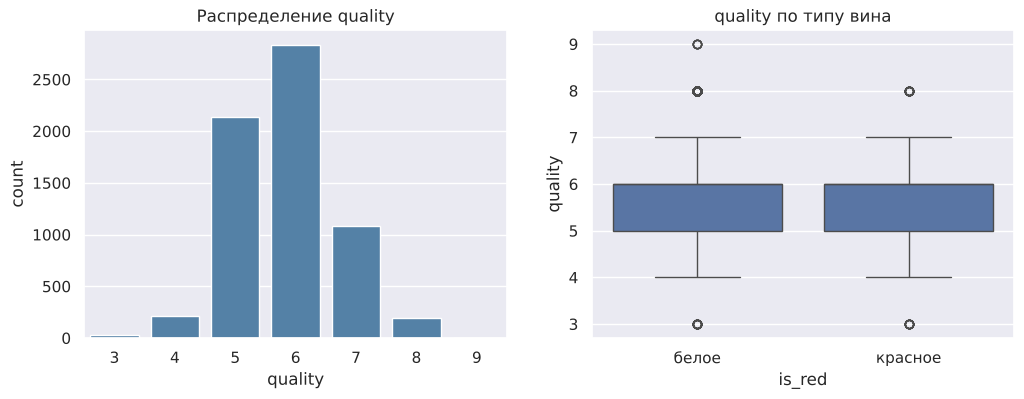

quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: proportion, dtype: float64

Среднее quality: белое = 5.878, красное = 5.636


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='quality', data=df, ax=ax[0], color='steelblue')
ax[0].set_title('Распределение quality')
sns.boxplot(x='is_red', y='quality', data=df, ax=ax[1])
ax[1].set_xticklabels(['белое', 'красное']); ax[1].set_title('quality по типу вина')
plt.show()
print(df.quality.value_counts(normalize=True).sort_index().round(3))
print('\nСреднее quality: белое = %.3f, красное = %.3f' % (white.quality.mean(), red.quality.mean()))

**Вывод.** Целевая переменная сильно сконцентрирована: оценки 5 и 6 составляют ~77% данных, а крайние классы (3, 4, 8, 9) редки (класс 9 — всего 5 вин из 6497). Значит, модель будет в основном учиться отличать «5» от «6» и «7», а редкие качества предсказывать плохо — это нужно проверить в анализе ошибок. Это же объясняет, почему стратифицированное разбиение здесь уместнее обычного. Красные вина в среднем оценены немного ниже белых (5.64 против 5.88), так что `is_red` может нести небольшой сигнал, но разница мала по сравнению со спредом оценок (std ≈ 0.87).

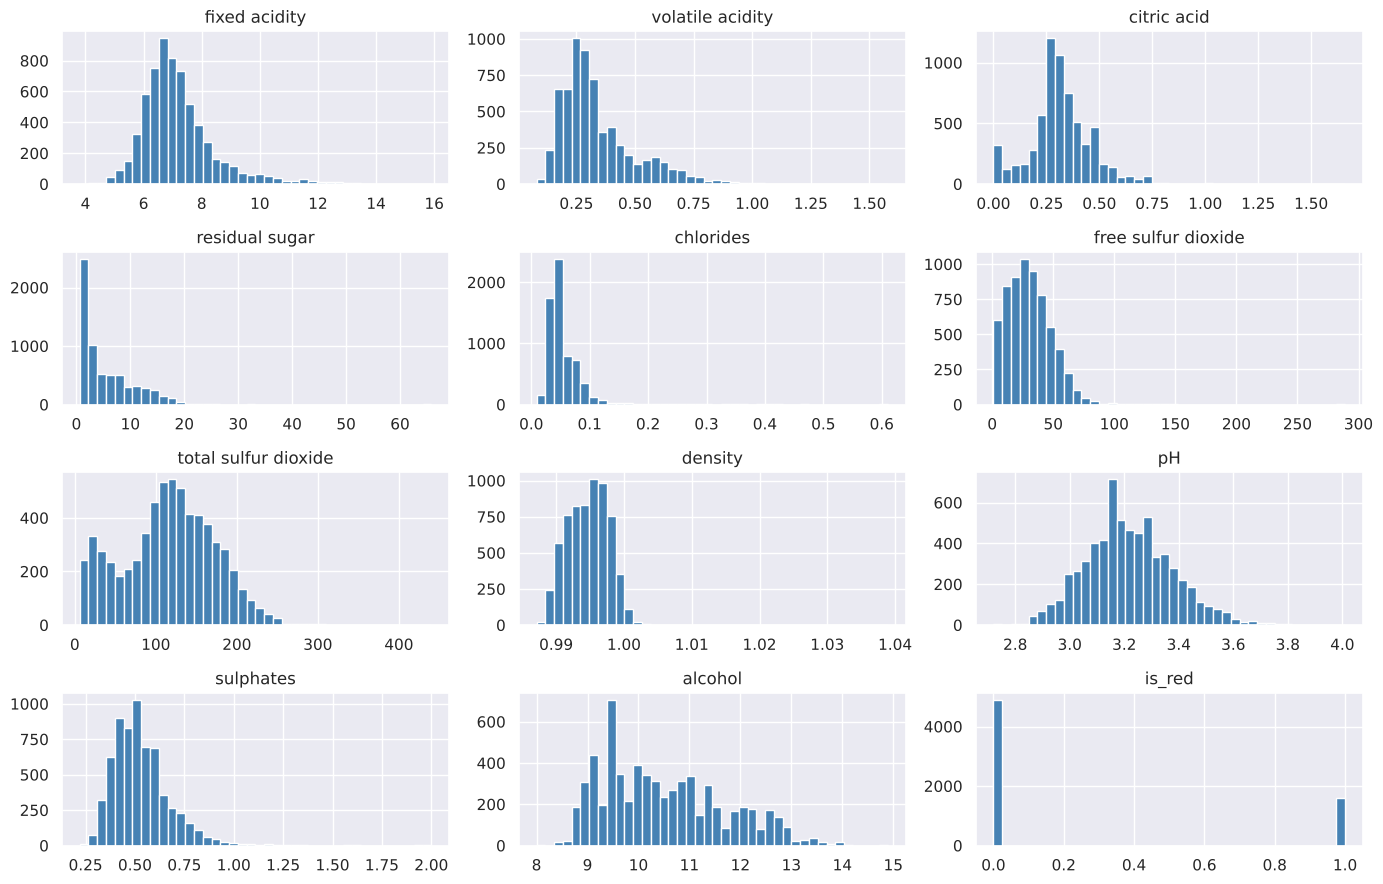

In [5]:
features = [c for c in df.columns if c not in ('quality',)]
df[features].hist(bins=40, figsize=(14, 9), color='steelblue')
plt.tight_layout(); plt.show()

**Вывод.** Многие признаки смещены вправо и имеют длинные хвосты (`residual sugar` до 65.8, `chlorides` до 0.61 при медиане 0.047, `free sulfur dioxide` до 289). Это не похоже на ошибки ввода — это реально отличающиеся вина (например, сладкие). Для линейной модели такие точки опасны (рычаги), поэтому масштабирование обязательно, а вот деревьям монотонные преобразования и выбросы почти не мешают, так что для них я ничего не обрезаю. Выбросы не удаляю: тест содержит такие же, и модель должна уметь с ними работать.

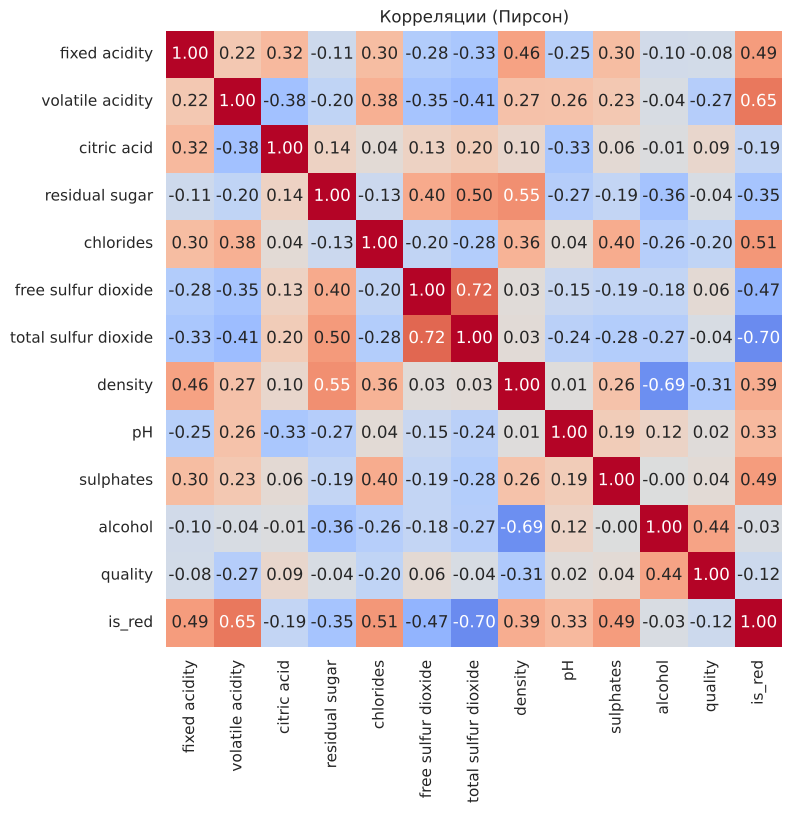

density                -0.306
volatile acidity       -0.266
chlorides              -0.201
is_red                 -0.119
fixed acidity          -0.077
total sulfur dioxide   -0.041
residual sugar         -0.037
pH                      0.020
sulphates               0.038
free sulfur dioxide     0.055
citric acid             0.086
alcohol                 0.444
Name: quality, dtype: float64


In [6]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar=False)
plt.title('Корреляции (Пирсон)'); plt.show()
print(corr['quality'].drop('quality').sort_values().round(3))

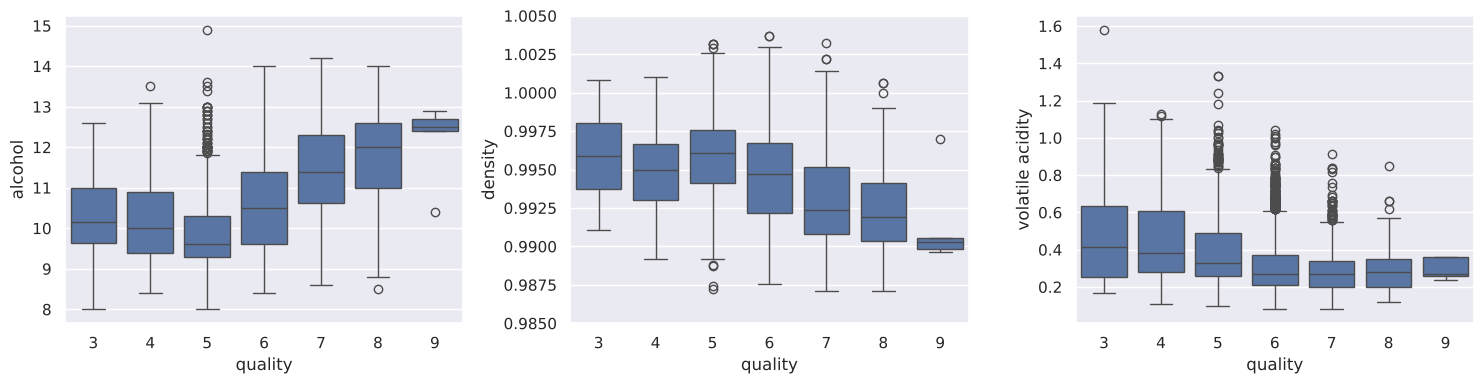

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x='quality', y='alcohol', data=df, ax=ax[0])
sns.boxplot(x='quality', y='density', data=df, ax=ax[1]); ax[1].set_ylim(0.985, 1.005)
sns.boxplot(x='quality', y='volatile acidity', data=df, ax=ax[2])
plt.tight_layout(); plt.show()

**Выводы по корреляциям.**
- `alcohol` — самый сильный линейный сигнал (r = +0.44): чем крепче вино, тем выше оценка. Средний alcohol растёт от 9.84 у вин с quality 5 до 11.4 у вин с quality 7. Этот признак точно нужно учитывать, но нельзя считать причиной оценки (подробнее в разделе 9).
- `density` (r = −0.31) — вероятно не самостоятельный фактор, а «заместитель» алкоголя: корреляция density–alcohol равна −0.69 (спирт легче воды), а density–residual sugar = +0.55. То есть эти три признака сильно связаны, и вклад density в `quality` по большей части объясняется алкоголем.
- `volatile acidity` (r = −0.27) — «уксусный» привкус, понятный механизм: чем больше, тем хуже оценка. `chlorides` (−0.20) — солёность, тоже ухудшает.
- Остальные признаки линейно почти не связаны с `quality` (|r| < 0.1), но это не значит, что они бесполезны: возможны нелинейные эффекты и взаимодействия, которые корреляция Пирсона не видит.
- Мультиколлинеарность: `free sulfur dioxide` и `total sulfur dioxide` (r = 0.72), `density` с тремя другими признаками. Для линейной регрессии это значит, что отдельные коэффициенты будут неустойчивыми и их нельзя читать как «чистый» вклад признака.
- Красное и белое вино заметно отличаются по химии (например, `volatile acidity` 0.53 против 0.28, `total sulfur dioxide` 46 против 138), поэтому `is_red` оставляем в признаках.

In [8]:
dup_mask = df.duplicated(keep=False)
print('Строк, входящих в группы дубликатов:', dup_mask.sum())
print('Лишних копий (drop_duplicates убрал бы):', df.duplicated().sum(), 'из', len(df))

Строк, входящих в группы дубликатов: 2169
Лишних копий (drop_duplicates убрал бы): 1177 из 6497


**Вывод.** 1177 из 6497 строк (~18%) — точные копии других строк. Это могут быть разные бутылки одного вина, оценённые одинаково, но для эксперимента важно другое: при случайном разбиении копии одной строки окажутся и в train, и в test, и модель, способная запоминать (Random Forest, глубокий бустинг), получит завышенную оценку. Я оставляю дубликаты в основном эксперименте, потому что скрытый тест, скорее всего, получен таким же случайным разбиением, но в разделе 8 отдельно проверяю, насколько это меняет результаты.

## 2. Подготовка выборок

Делим данные **один раз** в самом начале. Всё дальнейшее (подбор гиперпараметров, масштабирование, выбор модели) использует только `train`; `test` открывается один раз для финальной оценки.

In [9]:
X = df.drop(columns='quality')
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print('train:', X_train.shape, '| test:', X_test.shape)
print(pd.DataFrame({'train': y_train.value_counts(normalize=True).sort_index(),
                    'test':  y_test.value_counts(normalize=True).sort_index()}).round(4))

# единая схема кросс-валидации для всех моделей (только на train)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

train: (5197, 12) | test: (1300, 12)
          train    test
quality                
3        0.0046  0.0046
4        0.0333  0.0331
5        0.3290  0.3292
6        0.4366  0.4362
7        0.1661  0.1662
8        0.0296  0.0300
9        0.0008  0.0008


**Что выбрано и почему.**
- **Размер:** 80% / 20% → 5197 объектов в train и 1300 в test. 80% оставляют достаточно данных для обучения (особенно для деревьев), а 1300 объектов в тесте дают достаточно устойчивую оценку RMSE (95% доверительный интервал порядка ±0.03, см. раздел 5).
- **Способ:** случайное разбиение со **стратификацией по `quality`**: классы очень несбалансированы (класс 9 — 5 объектов), и без стратификации в тесте мог бы вообще не оказаться класс 8 или 9, а метрики на разных разбиениях сильно «плавали» бы. Таблица выше показывает, что доли классов в train и test совпадают. Временной или групповой структуры в данных нет, поэтому случайное разбиение допустимо (оговорка про дубликаты — в разделе 8).
- **`random_state=42`** зафиксирован для воспроизводимости; все модели используют одно и то же разбиение и одну схему 5-fold CV на train.
- **Что даёт CV:** гиперпараметры подбираются по кросс-валидации внутри train, тест не трогается до финальной оценки.

**Почему нельзя многократно оценивать модели на одном тесте.** Каждый раз, когда мы выбираем модель, признаки или параметры по тесту, информация о тесте «просачивается» в решение: выбор подгоняется под конкретные 1300 объектов, и оценка становится оптимистичной (из многих кандидатов выигрывает тот, кому повезло на этом тесте). Итоговая цифра перестаёт быть честной оценкой на новых данных, а тест перестаёт быть «скрытым». Поэтому для подбора есть CV на train, а тест используется один раз.

## 3. Метрики и baseline

In [10]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def evaluate(y_true, y_pred):
    return {'RMSE': rmse(y_true, y_pred), 'MAE': mean_absolute_error(y_true, y_pred)}

# Константы выбираем ТОЛЬКО по train.
# RMSE минимизируется средним, MAE — медианой.
c_mean = y_train.mean()
c_median = y_train.median()
print('mean(train) = %.4f, median(train) = %.1f' % (c_mean, c_median))

results = {}
results['Baseline (среднее)'] = evaluate(y_test, np.full(len(y_test), c_mean))
pd.DataFrame({'Baseline (среднее)': results['Baseline (среднее)'],
              'Baseline (медиана) — для сравнения': evaluate(y_test, np.full(len(y_test), c_median))}).T.round(4)

mean(train) = 5.8182, median(train) = 6.0


,RMSE,MAE
Baseline (среднее),0.8738,0.6861
Baseline (медиана) — для сравнения,0.8923,0.6377


**Вывод.** Константа выбирается по обучающей выборке и зависит от метрики: RMSE минимизируется **средним** (5.818), MAE — **медианой** (6.0). Основная метрика — RMSE, поэтому в итоговую таблицу идёт baseline по среднему (RMSE = 0.874 — это почти std целевой переменной, как и должно быть). Для сравнения видно: медиана хуже по RMSE (0.892), но лучше по MAE (0.638 против 0.686). Любая модель, которая не побеждает 0.874 по RMSE, не извлекает из признаков ничего полезного.

## 4. Модели

### 4.1 Линейная регрессия

In [11]:
lin = make_pipeline(StandardScaler(), LinearRegression())
cv_rmse = -cross_val_score(lin, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
print('CV RMSE на train: %.4f ± %.4f' % (cv_rmse.mean(), cv_rmse.std()))

lin.fit(X_train, y_train)
pred_lin = lin.predict(X_test)
results['Linear Regression'] = evaluate(y_test, pred_lin)
print('Test:', {k: round(v, 4) for k, v in results['Linear Regression'].items()})

CV RMSE на train: 0.7377 ± 0.0131
Test: {'RMSE': np.float64(0.728), 'MAE': 0.5678}


,coef_scaled,coef_raw,abs_scaled
density,-0.3230,-107.2543,0.3230
residual sugar,0.3086,0.0645,0.3086
alcohol,0.2558,0.2152,0.2558
volatile acidity,-0.2423,-1.4620,0.2423
is_red,0.1335,0.3089,0.1335
fixed acidity,0.1121,0.0872,0.1121
sulphates,0.1093,0.7447,0.1093
total sulfur dioxide,-0.0909,-0.0016,0.0909
pH,0.0881,0.5483,0.0881
free sulfur dioxide,0.0861,0.0049,0.0861


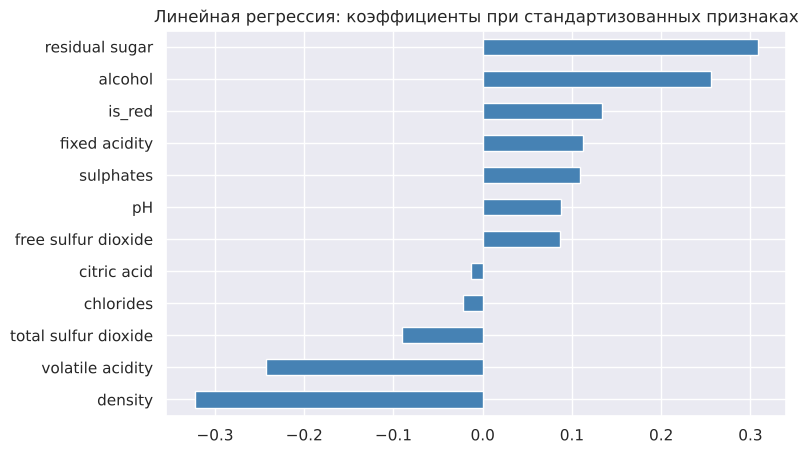

In [12]:
# Коэффициенты: на стандартизованных признаках (сопоставимы) и на исходных масштабах (не сопоставимы)
raw = LinearRegression().fit(X_train, y_train)
coef = pd.DataFrame({
    'coef_scaled': lin[-1].coef_,
    'coef_raw': raw.coef_,
}, index=X.columns)
coef['abs_scaled'] = coef.coef_scaled.abs()
coef = coef.sort_values('abs_scaled', ascending=False)
display(coef.round(4))

plt.figure(figsize=(8, 5))
coef.coef_scaled.sort_values().plot.barh(color='steelblue')
plt.title('Линейная регрессия: коэффициенты при стандартизованных признаках'); plt.show()

**Выводы.**
- Линейная регрессия **лучше baseline** (RMSE 0.728 против 0.874), то есть признаки действительно несут информацию, но **порог 0.70 она не проходит**. CV-оценка на train (0.738) близка к тесту (0.728), значит переобучения нет, а проблема в недообучении: зависимость `quality` от признаков заметно нелинейна.
- **Масштабирование.** Сравнивать `coef_raw` нельзя: коэффициент при `density` (−107) огромен лишь потому, что density меняется в пределах сотых долей, а `total sulfur dioxide` (−0.0016) мал, потому что измеряется сотнями. После `StandardScaler` коэффициент показывает изменение `quality` при росте признака на одно стандартное отклонение, и их уже можно сравнивать между собой. Само масштабирование предсказания линейной регрессии не меняет, оно нужно для интерпретации (и для регуляризованных моделей).
- **Что получилось:** самые большие по модулю стандартизованные коэффициенты у `density` (−0.32), `residual sugar` (+0.31), `alcohol` (+0.26) и `volatile acidity` (−0.24). Но это **нужно читать осторожно**: `density`, `residual sugar` и `alcohol` сильно связаны между собой (r от 0.55 до 0.69 по модулю), и при мультиколлинеарности линейная модель «перераспределяет» эффект между ними. Так, `residual sugar` имеет почти нулевую корреляцию с `quality` (−0.04), но положительный коэффициент: он нужен модели, чтобы скорректировать вклад `density`, а не потому что сахар сам по себе повышает оценку. Знак и величина отдельных коэффициентов здесь ненадёжны; более надёжен вывод про `volatile acidity` (−) и `alcohol` (+).

### 4.1б Линейная модель со сплайнами и взаимодействиями (Ridge)

Простая линейная регрессия (RMSE 0.728) не проходит порог 0.70: зависимость `quality` от признаков нелинейна. Модель остаётся линейной *по параметрам*, но признаки строятся умнее:
1. **log1p** для скошенных признаков с длинным хвостом;
2. **SplineTransformer** (кубические B-сплайны, узлы по квантилям) — каждый признак раскладывается по гибким базисным функциям, и модель может описывать нелинейную (в том числе немонотонную) зависимость от каждого признака;
3. **попарные взаимодействия** исходных признаков (включая `is_red`), чтобы учесть, что эффект признака зависит от остальных;
4. **Ridge** (L2) — признаков становится много (~100), и они коррелированы.

Число узлов сплайна и силу регуляризации выбираем кросс-валидацией **на train**.

In [13]:
SKEWED = ['residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates', 'volatile acidity']

def log_skewed(X):
    X = X.copy()
    for c in SKEWED:
        X[c] = np.log1p(X[c])
    return X

def make_lin_fe(n_knots=6, alpha=100):
    n = X_train.shape[1]            # 12 признаков: 11 непрерывных + is_red (последний)
    splines = ColumnTransformer([
        ('spline', SplineTransformer(n_knots=n_knots, degree=3, knots='quantile'), list(range(n - 1))),
        ('is_red', 'passthrough', [n - 1]),
    ])
    return Pipeline([
        ('log', FunctionTransformer(log_skewed)),
        ('scale1', StandardScaler()),
        ('features', FeatureUnion([
            ('splines', splines),
            ('pairwise', PolynomialFeatures(2, include_bias=False, interaction_only=True)),
        ])),
        ('scale2', StandardScaler()),
        ('ridge', Ridge(alpha=alpha)),
    ])

assert list(X_train.columns)[-1] == 'is_red'
lin_fe_search = GridSearchCV(make_lin_fe(), {'features__splines__spline__n_knots': [4, 5, 6],
                                              'ridge__alpha': [30, 100, 300]},
                             cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
lin_fe_search.fit(X_train, y_train)
print('Лучшие параметры:', lin_fe_search.best_params_)
print('CV RMSE на train: %.4f' % -lin_fe_search.best_score_)
cvres = pd.DataFrame(lin_fe_search.cv_results_)
display(cvres.assign(cv_rmse=-cvres.mean_test_score).pivot(index='param_features__splines__spline__n_knots',
        columns='param_ridge__alpha', values='cv_rmse').round(4))

lin_fe = lin_fe_search.best_estimator_
pred_lin_fe = lin_fe.predict(X_test)
results['Linear Regression + FE (Ridge)'] = evaluate(y_test, pred_lin_fe)
print('Test:', {k: round(v, 4) for k, v in results['Linear Regression + FE (Ridge)'].items()})

Лучшие параметры: {'features__splines__spline__n_knots': 6, 'ridge__alpha': 100}
CV RMSE на train: 0.6952


param_ridge__alpha,30,100,300
param_features__splines__spline__n_knots,,,
4,0.7003,0.6988,0.6992
5,0.6985,0.6970,0.6970
6,0.6964,0.6952,0.6955


Test: {'RMSE': np.float64(0.686), 'MAE': 0.5375}


**Вывод.** RMSE падает с 0.728 до **0.686** (MAE 0.568 → 0.538), и модель проходит порог 0.70. Лучшая конфигурация по CV на train — 6 узлов сплайна, `alpha=100` (CV RMSE 0.695, близко к тесту, значит выбор не подогнан под тест); по таблице видно, что результат устойчив к параметрам (0.695–0.700). Откуда выигрыш:
- **Сплайны** позволяют каждому признаку иметь нелинейный (в том числе немонотонный) эффект, например «слишком мало и слишком много SO₂ плохо». Но сами по себе сплайны дают только ~0.70–0.71 (это проверено отдельно при разработке), то есть почти не помогают без взаимодействий.
- **Попарные взаимодействия** (в том числе с `is_red`) дают основной вклад: эффект одного признака зависит от других и от типа вина.
- **Ridge** не даёт коэффициентам разрастись при ~100 коррелирующих признаках. Степень 3 вместо взаимодействий второго порядка уже переобучается.

**Честная оговорка:** запас до порога небольшой. Bootstrap-интервал [0.655, 0.718] захватывает 0.70, а на данных без дубликатов (раздел 8) RMSE = 0.697, то есть почти на пороге. Возможно, около 0.69–0.70 — потолок для линейных моделей на этих данных: деревья заметно лучше за счёт автоматического поиска взаимодействий. Модель остаётся линейной по параметрам, но после сплайнов и взаимодействий отдельные коэффициенты интерпретировать нельзя — для анализа коэффициентов остаётся простая модель из 4.1.

### 4.2 Random Forest

In [14]:
rf_grid = {
    'n_estimators': [300],
    'max_features': [0.33, 0.5, 0.8],
    'min_samples_leaf': [1, 2, 4],
    'max_depth': [None, 20],
}
rf_search = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                         rf_grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1)
rf_search.fit(X_train, y_train)
print('Лучшие параметры:', rf_search.best_params_)
print('CV RMSE на train: %.4f' % -rf_search.best_score_)

rf = rf_search.best_estimator_
pred_rf = rf.predict(X_test)
results['Random Forest'] = evaluate(y_test, pred_rf)
print('Test:', {k: round(v, 4) for k, v in results['Random Forest'].items()})

Лучшие параметры: {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 300}
CV RMSE на train: 0.6130
Test: {'RMSE': np.float64(0.5932), 'MAE': 0.4247}


### 4.3 Gradient Boosting

In [15]:
gb_dist = {
    'n_estimators': [200, 400, 600],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'min_samples_leaf': [1, 5, 10],
    'subsample': [0.7, 0.85, 1.0],
}
gb_search = RandomizedSearchCV(GradientBoostingRegressor(random_state=RANDOM_STATE),
                               gb_dist, n_iter=30, cv=cv, scoring='neg_root_mean_squared_error',
                               random_state=RANDOM_STATE, n_jobs=-1)
gb_search.fit(X_train, y_train)
print('Лучшие параметры:', gb_search.best_params_)
print('CV RMSE на train: %.4f' % -gb_search.best_score_)

gb = gb_search.best_estimator_
pred_gb = gb.predict(X_test)
results['Gradient Boosting'] = evaluate(y_test, pred_gb)
print('Test:', {k: round(v, 4) for k, v in results['Gradient Boosting'].items()})

Лучшие параметры: {'subsample': 0.85, 'n_estimators': 600, 'min_samples_leaf': 1, 'max_depth': 6, 'learning_rate': 0.05}
CV RMSE на train: 0.6289
Test: {'RMSE': np.float64(0.6085), 'MAE': 0.4381}


## 5. Честное сравнение моделей

,RMSE,MAE,"vs baseline, RMSE"
Модель,,,
Baseline (среднее),0.8738,0.6861,0.0000
Linear Regression,0.7280,0.5678,0.1458
Linear Regression + FE (Ridge),0.6860,0.5375,0.1877
Random Forest,0.5932,0.4247,0.2806
Gradient Boosting,0.6085,0.4381,0.2652


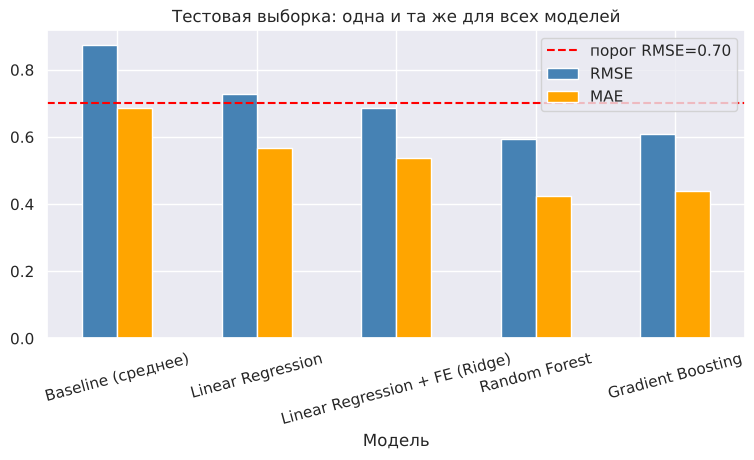

In [16]:
res = pd.DataFrame(results).T
res.index.name = 'Модель'
res['vs baseline, RMSE'] = res.loc['Baseline (среднее)', 'RMSE'] - res['RMSE']
display(res.round(4))

res[['RMSE', 'MAE']].plot.bar(figsize=(9, 4), color=['steelblue', 'orange'])
plt.axhline(0.70, color='red', ls='--', label='порог RMSE=0.70'); plt.legend()
plt.xticks(rotation=15); plt.title('Тестовая выборка: одна и та же для всех моделей'); plt.show()

In [17]:
# Оценка неопределённости: bootstrap по тестовым объектам (модели не переобучаются)
rng = np.random.RandomState(RANDOM_STATE)
preds = {'Linear Regression': pred_lin, 'Linear Regression + FE (Ridge)': pred_lin_fe, 'Random Forest': pred_rf, 'Gradient Boosting': pred_gb}
yt = y_test.values
idx = [rng.randint(0, len(yt), len(yt)) for _ in range(1000)]
boot = {n: np.array([rmse(yt[i], p[i]) for i in idx]) for n, p in preds.items()}
for n, b in boot.items():
    print('%-18s RMSE 95%% ДИ: [%.3f, %.3f]' % (n, *np.percentile(b, [2.5, 97.5])))
print('P(RF лучше GB по RMSE) = %.3f' % (boot['Random Forest'] < boot['Gradient Boosting']).mean())

Linear Regression  RMSE 95% ДИ: [0.694, 0.763]
Linear Regression + FE (Ridge) RMSE 95% ДИ: [0.655, 0.718]
Random Forest      RMSE 95% ДИ: [0.559, 0.626]
Gradient Boosting  RMSE 95% ДИ: [0.573, 0.644]
P(RF лучше GB по RMSE) = 0.986


**Результаты.** Все модели превзошли baseline (RMSE 0.874): простая линейная — на 0.15, линейная со сплайнами — на 0.19, Random Forest — на 0.28, Gradient Boosting — на 0.27. **Порог RMSE < 0.70 проходят Linear Regression + FE (0.686), Random Forest (0.593) и Gradient Boosting (0.609)**, простая линейная регрессия (0.728) — нет. Bootstrap-интервалы показывают, что деревья отделены от линейной модели уверенно (интервалы не пересекаются), а вот RF и GB между собой различаются слабо: разница 0.015 лежит внутри интервалов, хотя в 98.6% бутстрап-выборок RF оказывается чуть лучше.

**Почему так.**
- **Линейная модель** предполагает, что каждый признак вносит вклад независимо и линейно, а здесь это не так: эффект `alcohol`, кислотности и сернистого газа зависит от типа вина и от других признаков (красное и белое устроены по-разному), а признаки сильно коррелируют. Поэтому простая линейная модель упирается в потолок ~0.73; сплайны и взаимодействия частично снимают это ограничение (0.686), но деревья всё равно лучше.
- **Деревья** автоматически ловят нелинейность и взаимодействия признаков (в том числе разные режимы для красного и белого), не требуют масштабирования и устойчивы к выбросам и скошенным распределениям, а их ансамбли сглаживают шум одиночных деревьев.
- **RF чуть лучше GB** — не универсальное правило, а особенность этих данных: оценки дегустаторов шумные (субъективные, дискретные), а бустинг последовательно «подгоняет» остатки и склонен к подстройке под шум; случайный лес усредняет независимые деревья и устойчивее к шуму. Кроме того, в данных ~18% дубликатов, а глубокие деревья (min_samples_leaf=1) хорошо «запоминают» копии, попавшие и в train, и в test — это даёт преимущество моделям с большой ёмкостью (см. раздел 8). GB с более тщательной настройкой (например, меньшим шагом и ранней остановкой) мог бы сократить отставание.

### 5.1 Ансамбль (усреднение моделей)

Ошибки линейной модели, Random Forest, Extra Trees и Gradient Boosting устроены по-разному (линейная модель гладкая, деревья ловят пороги и взаимодействия), поэтому их усреднение обычно ошибается меньше, чем каждая модель по отдельности. Веса **равные** (простое среднее), они не подбираются по тесту. Extra Trees — ещё один ансамбль деревьев (с случайными порогами разбиения, поэтому он менее склонен подстраиваться под шум); его параметры выбраны по CV на train на этапе разработки.

In [18]:
et = ExtraTreesRegressor(n_estimators=500, max_features=0.5, min_samples_leaf=1, random_state=RANDOM_STATE, n_jobs=-1)
cv_et = -cross_val_score(et, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error').mean()
et.fit(X_train, y_train)
pred_et = et.predict(X_test)
print('Extra Trees: CV RMSE %.4f | test RMSE %.4f' % (cv_et, rmse(y_test, pred_et)))

pred_ens = np.mean([pred_lin_fe, pred_rf, pred_et, pred_gb], axis=0)
results['Ensemble (Lin-FE + RF + ET + GB)'] = evaluate(y_test, pred_ens)
preds['Ensemble (Lin-FE + RF + ET + GB)'] = pred_ens
print('Ensemble test:', {k: round(v, 4) for k, v in results['Ensemble (Lin-FE + RF + ET + GB)'].items()})

res = pd.DataFrame(results).T
res.index.name = 'Модель'
res['vs baseline, RMSE'] = res.loc['Baseline (среднее)', 'RMSE'] - res['RMSE']
display(res.round(4))

Extra Trees: CV RMSE 0.6000 | test RMSE 0.5764
Ensemble test: {'RMSE': np.float64(0.5915), 'MAE': 0.4335}


,RMSE,MAE,"vs baseline, RMSE"
Модель,,,
Baseline (среднее),0.8738,0.6861,0.0000
Linear Regression,0.7280,0.5678,0.1458
Linear Regression + FE (Ridge),0.6860,0.5375,0.1877
Random Forest,0.5932,0.4247,0.2806
Gradient Boosting,0.6085,0.4381,0.2652
Ensemble (Lin-FE + RF + ET + GB),0.5915,0.4335,0.2822


**Вывод.** На исходном разбиении ансамбль (0.5915) практически не отличается от Random Forest (0.5932) и немного хуже одиночного Extra Trees (0.576, он сильнее всех «запоминает» дубликаты); это в пределах шума. Главный выигрыш ансамбля виден в разделе 8, на данных без дубликатов: **0.6735** против 0.680 (RF), 0.696 (GB) и 0.697 (линейная с FE). То есть усреднение разнородных моделей действительно снижает ошибку на новых, не встречавшихся в обучении винах, хотя выигрыш скромный (~0.005–0.02): ошибки моделей сильно коррелируют, потому что значительная часть ошибки — шум самих оценок дегустаторов, который не убрать ни одной моделью.

## 6. Feature importance

,RF (impurity),GB (impurity),RF (permutation),GB (permutation),LR |coef| (scaled)
alcohol,0.176,0.239,0.271,0.224,0.143
volatile acidity,0.110,0.128,0.126,0.117,0.136
density,0.107,0.067,0.083,0.078,0.181
free sulfur dioxide,0.085,0.087,0.111,0.130,0.048
chlorides,0.083,0.063,0.062,0.036,0.012
total sulfur dioxide,0.079,0.079,0.069,0.120,0.051
residual sugar,0.076,0.080,0.057,0.083,0.173
sulphates,0.075,0.077,0.079,0.090,0.061
citric acid,0.072,0.057,0.059,0.040,0.008
pH,0.070,0.067,0.038,0.042,0.049


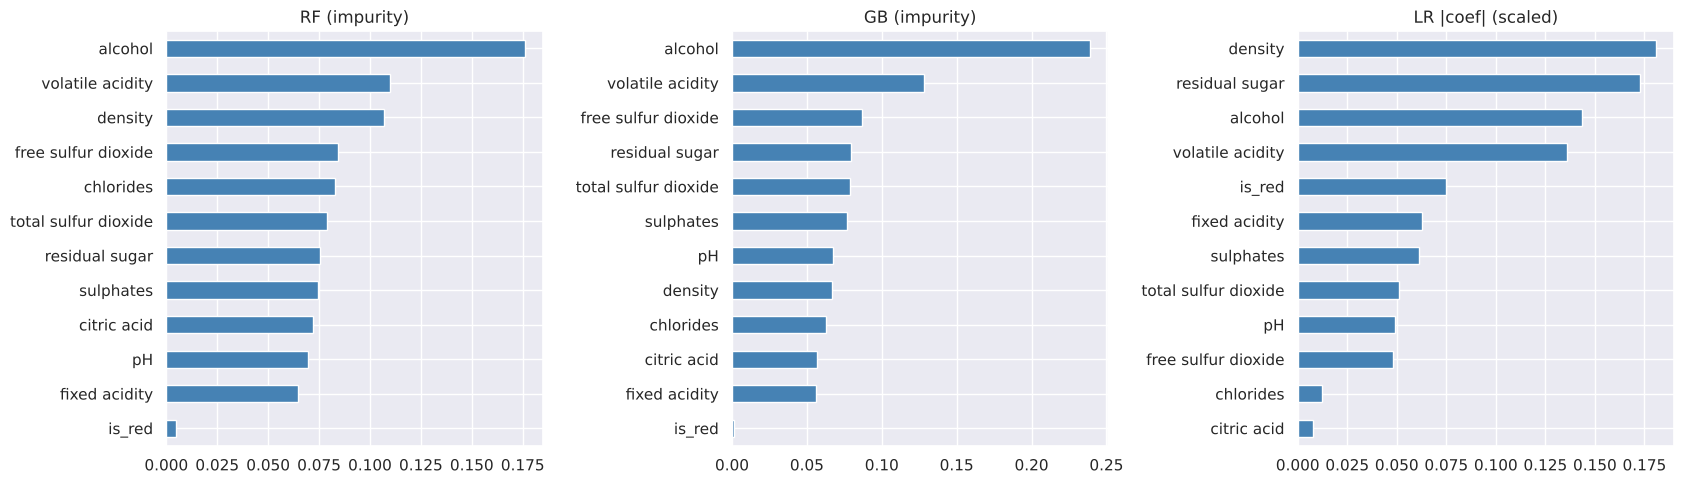

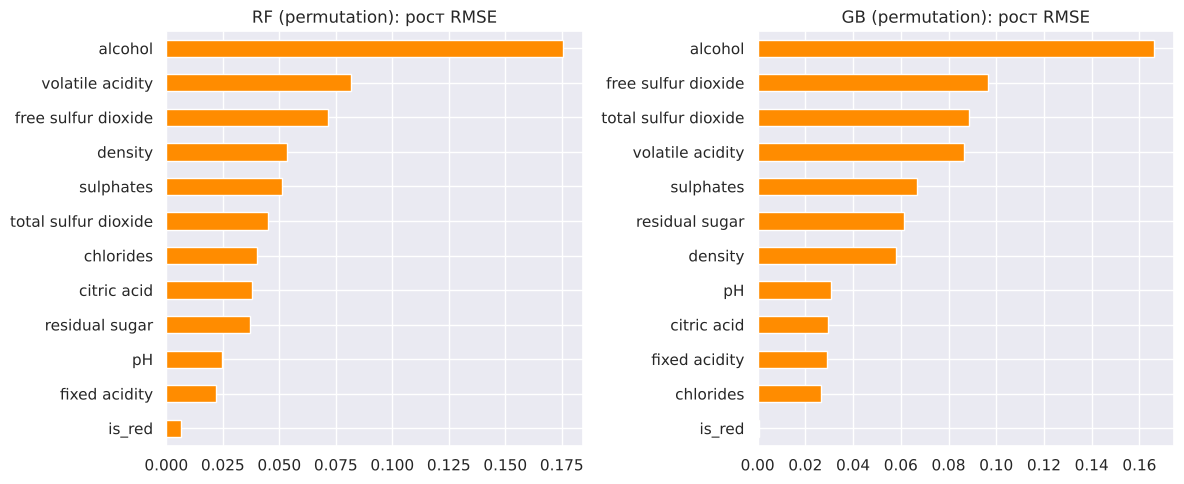

Ранги признаков (1 — самый важный):


,RF (impurity),GB (impurity),RF (permutation),GB (permutation),LR |coef| (scaled)
alcohol,1,1,1,1,3
volatile acidity,2,2,2,4,4
density,3,8,4,7,1
free sulfur dioxide,4,3,3,2,10
chlorides,5,9,7,11,11
total sulfur dioxide,6,5,6,3,8
residual sugar,7,4,9,6,2
sulphates,8,6,5,5,7
citric acid,9,10,8,9,12
pH,10,7,10,8,9


In [19]:
imp = pd.DataFrame(index=X.columns)
imp['RF (impurity)'] = rf.feature_importances_
imp['GB (impurity)'] = gb.feature_importances_

# permutation importance — рост RMSE при перемешивании признака (считаем на test только для интерпретации,
# никаких решений по нему не принимается)
for name, m in [('RF (permutation)', rf), ('GB (permutation)', gb)]:
    pi = permutation_importance(m, X_test, y_test, scoring='neg_root_mean_squared_error',
                                n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
    imp[name] = pi.importances_mean

imp['LR |coef| (scaled)'] = lin[-1].coef_.__abs__()
imp_norm = imp / imp.sum()
display(imp_norm.sort_values('RF (impurity)', ascending=False).round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 5), sharey=False)
for a, col in zip(ax, ['RF (impurity)', 'GB (impurity)', 'LR |coef| (scaled)']):
    imp_norm[col].sort_values().plot.barh(ax=a, color='steelblue'); a.set_title(col)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, col in zip(ax, ['RF (permutation)', 'GB (permutation)']):
    imp[col].sort_values().plot.barh(ax=a, color='darkorange'); a.set_title(col + ': рост RMSE')
plt.tight_layout(); plt.show()

ranks = imp_norm.rank(ascending=False).astype(int)
print('Ранги признаков (1 — самый важный):')
display(ranks.sort_values('RF (impurity)'))

**Выводы.**
- **Самый важный признак во всех моделях — `alcohol`** (RF: 17.6% суммарной важности, GB: 23.9%, по permutation importance — ещё заметнее: 0.27 и 0.22 прироста RMSE при перемешивании). Это согласуется с EDA (самая большая корреляция с `quality`, r = 0.44) и с линейной регрессией (стандартизованный коэффициент +0.26).
- **На втором месте — `volatile acidity`** у обоих ансамблей, что также совпадает с EDA (r = −0.27) и с линейной моделью. Поэтому эти два признака можно считать наиболее надёжно связанными с оценкой.
- **Расхождения.** Линейная регрессия ставит на первое место `density` и `residual sugar`, а деревья — нет (у GB `density` лишь 8-й). Это ровно тот эффект мультиколлинеарности, о котором шла речь выше: линейная модель делит влияние между связанными признаками, а деревья, выбрав `alcohol`, уже не нуждаются в `density`. `free sulfur dioxide` и `total sulfur dioxide`, напротив, важны для деревьев (3-е–6-е места), хотя линейно почти не связаны с `quality`: вероятно, у них нелинейный (немонотонный) эффект — слишком мало и слишком много SO₂ плохо, — что корреляция Пирсона не видит.
- **Impurity importance vs permutation.** Встроенная важность (по уменьшению неоднородности) склонна завышать значимость непрерывных признаков с большим числом разных значений и размазывается между коррелированными признаками. Permutation importance (измеряет реальное падение качества на тесте) ранжирует признаки похожим образом, но её значения более контрастны. В целом топ-2 стабилен, а середина рейтинга (`chlorides`, `sulphates`, `citric acid`, `pH`) зависит от метода и модели и интерпретации не поддаётся.
- `is_red` важен слабо (ранг 12): большую часть различий между типами вина деревья уже восстанавливают по другим признакам (`total sulfur dioxide`, `volatile acidity`, `residual sugar` у красных и белых заметно отличаются).

**Можно ли по feature importance утверждать, что изменение признака *является причиной* изменения качества? Нет.** Важность показывает, насколько признак помогает модели *предсказывать* `quality` в имеющихся наблюдательных данных, то есть измеряет статистическую связь, а не причинность. Причины: (1) **конфаундеры** — алкоголь может быть связан с сортом винограда, регионом, стилем производства, и именно они влияют на оценку; (2) **коррелированные признаки** делят важность между собой или подменяют друг друга (`density` ↔ `alcohol`); (3) данные не экспериментальные: мы не меняли концентрацию спирта при фиксированных остальных свойствах; (4) оценка — субъективное мнение дегустаторов, и сами признаки могут быть следствием технологических решений. Чтобы говорить о причинности, нужен эксперимент (менять одну переменную, контролируя остальные) или методы причинного вывода.

## 7. Анализ ошибок лучшей модели

Лучшая модель по test RMSE: Random Forest


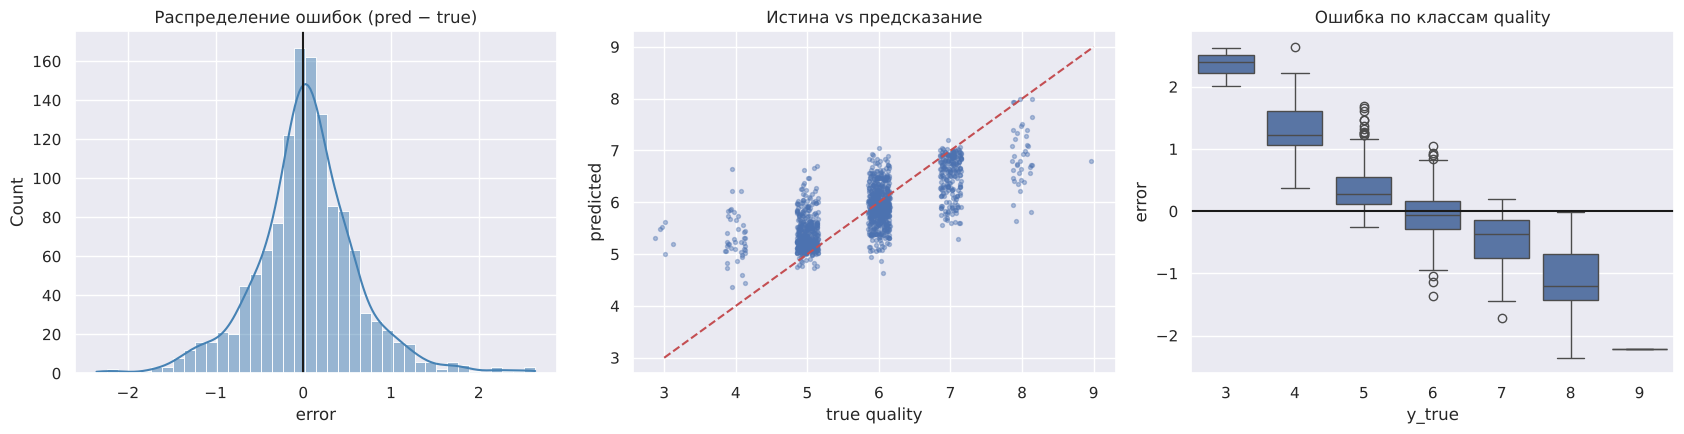

,n,bias,MAE,RMSE,pred_mean
y_true,,,,,
3,6,2.358,2.358,2.368,5.358
4,43,1.313,1.313,1.390,5.313
5,428,0.377,0.387,0.506,5.377
6,567,-0.058,0.293,0.379,5.942
7,216,-0.482,0.486,0.629,6.518
8,39,-1.093,1.093,1.234,6.907
9,1,-2.210,2.210,2.210,6.790


Доля |ошибки| < 0.5: 0.685 | < 1: 0.901 | > 1.5: 0.0246


In [20]:
# лучшая из обязательных моделей (ансамбль отличается от неё незначимо: 0.5915 против 0.5932)
best_name = res.loc[['Random Forest', 'Gradient Boosting'], 'RMSE'].idxmin()
best_pred = preds[best_name]
print('Лучшая модель по test RMSE:', best_name)

err = pd.DataFrame({'y_true': y_test.values, 'y_pred': best_pred}, index=y_test.index)
err['error'] = err.y_pred - err.y_true
err['abs_error'] = err.error.abs()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(err.error, bins=40, kde=True, ax=ax[0], color='steelblue')
ax[0].axvline(0, color='k'); ax[0].set_title('Распределение ошибок (pred − true)')
jit = np.random.RandomState(0).uniform(-0.15, 0.15, len(err))
ax[1].scatter(err.y_true + jit, err.y_pred, s=8, alpha=0.4)
ax[1].plot([3, 9], [3, 9], 'r--'); ax[1].set_xlabel('true quality'); ax[1].set_ylabel('predicted'); ax[1].set_title('Истина vs предсказание')
sns.boxplot(x='y_true', y='error', data=err, ax=ax[2]); ax[2].axhline(0, color='k'); ax[2].set_title('Ошибка по классам quality')
plt.tight_layout(); plt.show()

by_q = err.groupby('y_true').agg(n=('error', 'size'), bias=('error', 'mean'),
                                 MAE=('abs_error', 'mean'),
                                 RMSE=('error', lambda e: np.sqrt((e**2).mean())),
                                 pred_mean=('y_pred', 'mean')).round(3)
display(by_q)
print('Доля |ошибки| < 0.5: %.3f | < 1: %.3f | > 1.5: %.4f' % (
    (err.abs_error < .5).mean(), (err.abs_error < 1).mean(), (err.abs_error > 1.5).mean()))

In [21]:
worst = err.sort_values('abs_error', ascending=False).head(10)
worst = worst.join(X_test)
display(worst.round(3))

# контекст: чем худшие объекты отличаются от типичных (средние значения признаков)
ctx = pd.DataFrame({'worst-10': X_test.loc[worst.index].mean(), 'test (все)': X_test.mean()})
display(ctx.round(3))

,y_true,y_pred,error,abs_error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
6107,4,6.643,2.643,2.643,5.8,0.260,0.30,2.60,0.034,75.0,129.0,0.990,3.20,0.38,11.5,0
2339,3,5.620,2.620,2.620,6.9,0.390,0.40,4.60,0.022,5.0,19.0,0.992,3.31,0.37,12.6,0
1850,3,5.520,2.520,2.520,8.5,0.260,0.21,16.20,0.074,41.0,197.0,0.998,3.02,0.50,9.8,0
3287,3,5.490,2.490,2.490,6.7,0.250,0.26,1.55,0.041,118.5,216.0,0.995,3.55,0.63,9.4,0
3005,8,5.643,-2.357,2.357,8.2,0.220,0.36,6.80,0.034,12.0,90.0,0.994,3.01,0.38,10.5,0
1374,3,5.310,2.310,2.310,6.8,0.815,0.00,1.20,0.267,16.0,29.0,0.995,3.32,0.51,9.8,1
5369,4,6.220,2.220,2.220,7.4,0.270,0.31,2.40,0.014,15.0,143.0,0.991,3.03,0.65,12.0,0
3715,4,6.213,2.213,2.213,6.8,0.200,0.27,1.20,0.034,19.0,68.0,0.990,3.14,0.37,11.7,0
2426,9,6.790,-2.210,2.210,7.4,0.240,0.36,2.00,0.031,27.0,139.0,0.991,3.28,0.48,12.5,0
1469,3,5.203,2.203,2.203,7.3,0.980,0.05,2.10,0.061,20.0,49.0,0.997,3.31,0.55,9.7,1


,worst-10,test (все)
fixed acidity,7.180,7.193
volatile acidity,0.388,0.338
citric acid,0.252,0.321
residual sugar,4.065,5.313
chlorides,0.061,0.056
free sulfur dioxide,34.850,30.435
total sulfur dioxide,107.900,114.867
density,0.993,0.995
pH,3.217,3.218
sulphates,0.482,0.529


**Выводы по ошибкам Random Forest (лучшая из обязательных моделей).**
- **В целом всё неплохо:** у 68.5% объектов ошибка меньше 0.5, у 90% — меньше 1, и лишь 2.5% объектов имеют ошибку больше 1.5. Распределение ошибок примерно симметрично и сосредоточено около нуля — это и даёт низкий RMSE.
- **Но качество неравномерно.** Таблица по классам показывает систематическое смещение **к середине** («регрессия к среднему»): на классах 3–4 модель завышает оценку (в среднем на +2.4 и +1.3), на классах 7–9 занижает (−0.5, −1.1, −2.2), а на самых массовых классах 5 и 6 смещение минимально, а MAE наименьший (0.39 и 0.29). Общая метрика хорошая именно потому, что объекты середины составляют ~77% выборки; на «краях» модель по сути предсказывает «обычное вино».
- **Почему редкие классы предсказываются хуже:** (1) примеров мало (в train всего ~24 вина класса 3 и ~170 класса 4), и дерево не набирает статистики для таких листьев; (2) при минимизации квадратичной ошибки выгоднее предсказывать значение, близкое к среднему, чем рисковать на редких классах; (3) признаки слабо различают «очень плохое» и «среднее» вино — их химический профиль перекрывается; (4) сама оценка шумная: разные дегустаторы могли поставить 3 и 5 почти одинаковому вину.
- **Крупнейшие ошибки** — это почти всегда редкие классы: вина с реальной оценкой 3 и 4, которые по химии выглядят как обычные (например, объект 3287: предсказано 5.5 при истинной 3 — его `total sulfur dioxide` 216 и `alcohol` 9.4 типичны для рядового вина, ничто в таблице не указывает на брак), и вина с оценкой 8–9 (объект 2426: истина 9, предсказание 6.8 — при высоком alcohol 12.5 модель дала хороший, но не выдающийся прогноз). Худшие 10 объектов в среднем мало отличаются по признакам от типичных (средние значения в таблице выше близки к средним по тесту), то есть причина ошибок не в аномальных значениях признаков, а в том, что в измеренных характеристиках нет информации, объясняющей экстремальную оценку (вкус, аромат, дефекты, не попавшие в датасет), либо в субъективности оценки.
- **Практический вывод:** если важно находить именно очень плохие или выдающиеся вина, одной RMSE недостаточно; нужны метрики по классам, взвешивание редких классов или постановка задачи как классификации.

## 8. Проверка на утечку через дубликаты

In [22]:
# В данных ~18% строк — полные дубликаты. При случайном разбиении копии одного вина попадают и в train, и в test.
# Проверяем, как это влияет на оценку: убираем дубликаты ДО разбиения и повторяем весь протокол.
df_u = df.drop_duplicates().reset_index(drop=True)
Xu, yu = df_u.drop(columns='quality'), df_u['quality']
Xu_tr, Xu_te, yu_tr, yu_te = train_test_split(Xu, yu, test_size=0.2, random_state=RANDOM_STATE, stratify=yu)

# те же найденные гиперпараметры, чтобы изолировать эффект дубликатов
chk = {}
pu_all = {}
chk['Baseline (среднее)'] = evaluate(yu_te, np.full(len(yu_te), yu_tr.mean()))
for n, m in [('Linear Regression', make_pipeline(StandardScaler(), LinearRegression())),
             ('Linear Regression + FE (Ridge)', make_lin_fe(lin_fe_search.best_params_['features__splines__spline__n_knots'], lin_fe_search.best_params_['ridge__alpha'])),
             ('Random Forest', RandomForestRegressor(**rf_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1)),
             ('Gradient Boosting', GradientBoostingRegressor(**gb_search.best_params_, random_state=RANDOM_STATE))]:
    pu = m.fit(Xu_tr, yu_tr).predict(Xu_te); chk[n] = evaluate(yu_te, pu); pu_all[n] = pu
pu_et = ExtraTreesRegressor(n_estimators=500, max_features=0.5, min_samples_leaf=1, random_state=RANDOM_STATE, n_jobs=-1).fit(Xu_tr, yu_tr).predict(Xu_te)
chk['Ensemble (Lin-FE + RF + ET + GB)'] = evaluate(yu_te, np.mean([pu_all['Linear Regression + FE (Ridge)'], pu_all['Random Forest'], pu_et, pu_all['Gradient Boosting']], axis=0))
print('Объектов после удаления дубликатов:', len(df_u), '| test:', len(yu_te))
cmp = pd.concat({'исходные данные': pd.DataFrame(results).T, 'без дубликатов': pd.DataFrame(chk).T}, axis=1)
display(cmp.round(4))

Объектов после удаления дубликатов: 5320 | test: 1064


исходные данные         без дубликатов  \
                                            RMSE     MAE           RMSE   
Baseline (среднее)                        0.8738  0.6861         0.8801   
Linear Regression                         0.7280  0.5678         0.7292   
Linear Regression + FE (Ridge)            0.6860  0.5375         0.6969   
Random Forest                             0.5932  0.4247         0.6798   
Gradient Boosting                         0.6085  0.4381         0.6959   
Ensemble (Lin-FE + RF + ET + GB)          0.5915  0.4335         0.6735   

                                          
                                     MAE  
Baseline (среднее)                0.6948  
Linear Regression                 0.5660  
Linear Regression + FE (Ridge)    0.5414  
Random Forest                     0.5256  
Gradient Boosting                 0.5300  
Ensemble (Lin-FE + RF + ET + GB)  0.5196

**Вывод.** После удаления дубликатов **линейные модели почти не меняются** (простая 0.728 → 0.729, со сплайнами 0.686 → 0.697): она не запоминает объекты, поэтому от утечки не выигрывает. Зато **Random Forest ухудшается с 0.593 до 0.680, Gradient Boosting — с 0.609 до 0.696**, то есть заметная часть преимущества деревьев в основном эксперименте объясняется тем, что копии тестовых вин присутствуют в обучении и модель их частично «вспоминает». Реальное качество на действительно новых винах ближе к 0.68–0.70 у деревьев, а линейная модель с FE даёт 0.697, то есть **вплотную к порогу 0.70**. Оба вывода верны одновременно: если скрытый тест устроен так же, как мой (случайное разбиение с дубликатами), то результат около 0.59–0.61 ожидаем; если же тест очищен от копий, запас до порога существенно меньше. Поэтому на защите честнее называть обе цифры. Лучший результат без дубликатов показывает ансамбль (0.6735), далее RF (0.680), GB (0.696), линейная с FE (0.697), то есть выводы о сравнении устойчивы.

Замечание: гиперпараметры подбирались на данных с дубликатами, поэтому их CV-оценки (RF 0.613, GB 0.629) также слегка оптимистичны: при кросс-валидации копии тоже попадают в разные фолды.

## 9. Ответы на вопросы из задания

**Что показывает MAE.** Среднюю абсолютную ошибку: насколько в среднем (в единицах `quality`) прогноз отличается от истины. Метрика линейная по ошибке, легко интерпретируется: MAE = 0.42 означает «в среднем ошибаемся на 0.42 балла». Оптимальный константный прогноз для MAE — медиана.

**Что показывает RMSE.** Корень из среднего квадрата ошибок — тоже в единицах `quality`, но с акцентом на крупные ошибки. Оптимальный константный прогноз для RMSE — среднее; RMSE равен стандартному отклонению остатков (если модель не смещена).

**Почему RMSE сильнее реагирует на большие ошибки.** Ошибки возводятся в квадрат до усреднения: ошибка 2 вносит вклад 4, то есть в 4 раза больше, чем ошибка 1, и в 16 раз больше, чем ошибка 0.5. Одна ошибка в 2.4 балла (как у вин класса 3) вносит столько же, сколько около 23 ошибок по 0.5.

**Почему MAE и RMSE у одной модели различаются.** Для любого набора ошибок RMSE ≥ MAE (неравенство между средним квадратичным и средним арифметическим), и чем неравномернее распределены ошибки, тем больше разрыв. Если все ошибки одинаковы по модулю, MAE = RMSE; если большинство ошибок маленькие, а немногие огромные, RMSE оказывается заметно больше. У нашего Random Forest MAE = 0.42, RMSE = 0.59 (отношение 1.4): типичная ошибка небольшая, но есть «хвост» редких крупных промахов на классах 3, 4, 8, 9, который MAE почти не видит, а RMSE подсвечивает.

**Дополнительные ответы по тексту задания** (про тест, масштабирование, сравнение feature importance и причинность) даны в соответствующих разделах выше: см. «Подготовка выборок», «Линейная регрессия», «Feature importance».

## 10. Итоги

| Модель | RMSE | MAE | Прошла порог 0.70 |
|---|---|---|---|
| Baseline (среднее) | 0.874 | 0.686 | нет |
| Linear Regression | 0.728 | 0.568 | нет |
| Linear Regression + FE (Ridge) | 0.686 | 0.538 | **да** |
| Random Forest | **0.593** | **0.425** | **да** |
| Gradient Boosting | 0.609 | 0.438 | **да** |
| Ensemble (Lin-FE + RF + ET + GB) | 0.592 | 0.434 | **да** |

1. Лучшая модель — Random Forest (RMSE 0.593). Gradient Boosting и линейная регрессия с подготовкой признаков (log + сплайны + взаимодействия + Ridge) тоже проходят порог 0.70; простая линейная регрессия — нет (0.728) из-за недообучения (нелинейность и мультиколлинеарность).
2. Главные признаки по всем моделям — `alcohol` и `volatile acidity`; это согласуется с EDA. Остальные расхождения между моделями объясняются мультиколлинеарностью (`density`, `residual sugar`, `alcohol`), и причинных выводов из важности признаков делать нельзя.
3. Модель хорошо предсказывает массовые оценки 5–6 и систематически «сжимает» редкие (3–4 завышает, 7–9 занижает).
4. Часть преимущества деревьев объясняется дубликатами в данных: без них RMSE ≈ 0.68–0.70, а у линейной модели с FE 0.697, то есть запас относительно порога невелик.
5. Ансамбль усреднением четырёх моделей даёт лучший результат на данных без дубликатов (0.6735); на исходном разбиении он не отличается от RF.
6. Что можно улучшить дальше: группировать дубликаты при разбиении и в CV, добавить регуляризацию или взаимодействия для линейной модели, подобрать GB точнее (меньший learning_rate + ранняя остановка), попробовать ансамблирование RF+GB.